# Single-Stock Risk Report

A parameterized report for one ticker over one date range, built on the cleaned table `ohlc_hw_cleaned` produced by
`01_data_cleaning.ipynb`. Run it directly, or with papermill by overriding the cell tagged `parameters`.

**Conventions**
- Prices are **adjusted close** (split- and dividend-adjusted), so returns reflect what a holder earned.
- Returns are daily **log returns**, `log(P_t / P_{t-1})`. Annualization uses 252 trading days.
- Calculations keep fractions (0.05 = 5%). Percentages appear only in displayed tables and charts.
- Anything that cannot be computed (too little history, zero volatility) is `NaN` in calculations and shown as `N/A`.

In [1]:
# Parameters
ticker = "AAPL"  # Stock ticker to analyze
start_date = "2024-01-01"  # Analysis start date
end_date = "2024-12-31"  # Analysis end date
db_path = "data/data.db"  # Database containing ohlc_hw_cleaned (relative to this notebook's folder)
volatility_window = 20  # Rolling window for volatility, in returns
ma_window = 50  # Moving-average window, in prices
risk_free_rate = 0.02  # Annual risk-free rate for the Sharpe ratio

In [2]:
import sqlite3
from contextlib import closing
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import scrapbook as sb
from IPython.display import display
from matplotlib.collections import LineCollection

%matplotlib inline
plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.width", 120)

TRADING_DAYS = 252

## Data loading

The inputs are checked before any query runs, so a bad request fails with a clear message instead of an empty chart.
The database is opened **read-only**, so the report cannot modify the data.

In [3]:
def validate_inputs(ticker, start_date, end_date, db_path, volatility_window, ma_window):
    """Check report parameters; return (ticker, start, end, database path) or raise ValueError."""
    if not isinstance(ticker, str) or not ticker.strip():
        raise ValueError("ticker must be a non-empty string")
    try:
        start, end = pd.Timestamp(start_date), pd.Timestamp(end_date)
    except (ValueError, TypeError) as exc:
        raise ValueError(f"dates must be YYYY-MM-DD strings: {exc}") from exc
    if start > end:
        raise ValueError(f"start_date {start.date()} is after end_date {end.date()}")
    for name, value in [("volatility_window", volatility_window), ("ma_window", ma_window)]:
        if not isinstance(value, int) or isinstance(value, bool) or value < 2:
            raise ValueError(f"{name} must be an integer >= 2, got {value!r}")
    database = Path(db_path).expanduser().resolve()
    if not database.is_file():
        raise FileNotFoundError(f"database not found: {database} (run 01_data_cleaning.ipynb first)")
    return ticker.strip().upper(), start, end, database


def load_prices(database, ticker, start, end):
    """Load one ticker's cleaned rows between two dates (inclusive), indexed by date."""
    query = """
        SELECT ts, open, high, low, close, adj_close, volume,
               return_outlier, return_verdict, zero_volume, adj_close_source,
               open_repaired, close_repaired, return_error_repaired
        FROM ohlc_hw_cleaned
        WHERE ticker = ? AND ts BETWEEN ? AND ?
        ORDER BY ts
    """
    with closing(sqlite3.connect(database.as_uri() + "?mode=ro", uri=True)) as conn:
        known = pd.read_sql_query("SELECT 1 FROM ohlc_hw_cleaned WHERE ticker = ? LIMIT 1", conn, params=(ticker,))
        if known.empty:
            raise ValueError(f"{ticker} is not in ohlc_hw_cleaned")
        df = pd.read_sql_query(query, conn, params=(ticker, start.strftime("%Y-%m-%d"), end.strftime("%Y-%m-%d")),
                               parse_dates=["ts"], index_col="ts")
    return df


ticker, start, end, database = validate_inputs(ticker, start_date, end_date, db_path, volatility_window, ma_window)
df = load_prices(database, ticker, start, end)

if len(df) < 2:
    raise ValueError(f"{ticker} has {len(df)} trading day(s) between {start.date()} and {end.date()}; "
                     "at least 2 prices are needed for a single return")

first_day, last_day = df.index[0], df.index[-1]
print(f"{ticker} from {start.date()} to {end.date()}: {len(df)} trading days")
print(f"Actual coverage: {first_day.date()} to {last_day.date()}")
if last_day < end or first_day > start:
    print("Note: the data does not cover the full requested range; all metrics describe the actual coverage above.")
if len(df) < volatility_window + 1:
    print(f"Insufficient history for rolling volatility: {volatility_window} returns need "
          f"{volatility_window + 1} prices, but only {len(df)} are available. Rolling volatility will be N/A.")

AAPL from 2024-01-01 to 2024-12-31: 202 trading days
Actual coverage: 2024-01-02 to 2024-10-18
Note: the data does not cover the full requested range; all metrics describe the actual coverage above.


In [4]:
cols = ["open", "high", "low", "close", "adj_close", "volume"]
display(df[cols].head())
display(df[cols].tail())

,open,high,low,close,adj_close,volume
ts,,,,,,
2024-01-02,187.15,188.44,183.89,185.64,184.94,82488674
2024-01-03,184.22,185.88,183.43,184.25,183.55,58414460
2024-01-04,182.15,183.09,180.88,181.91,181.22,71983570
2024-01-05,181.99,182.76,180.17,181.18,180.50,62379661
2024-01-08,182.09,185.60,181.50,185.56,184.86,59144470


,open,high,low,close,adj_close,volume
ts,,,,,,
2024-10-14,228.70,231.73,228.60,231.30,231.30,39882100
2024-10-15,233.61,237.49,232.37,233.85,233.85,64751400
2024-10-16,231.60,232.12,229.84,231.78,231.78,34082240
2024-10-17,233.43,233.85,230.52,232.15,232.15,32993810
2024-10-18,236.18,236.18,234.01,235.00,235.00,45441281


### Data notes

The cleaned table keeps every repair flag. This shows how many of the days in this report were repaired during
cleaning or flagged for review, so unusual numbers can be traced back to the data.

In [5]:
data_notes = pd.Series({
    "adj_close rebuilt from reference factor": int((df["adj_close_source"] != "vendor").sum()),
    "raw price repaired (impossible / data error)":
        int((df[["open_repaired", "close_repaired", "return_error_repaired"]].sum(axis=1) > 0).sum()),
    "zero-volume days (possibly stale)": int(df["zero_volume"].sum()),
    "extreme raw-return days (kept, flagged)": int(df["return_outlier"].sum()),
}, name="days")
display(data_notes.to_frame())
flagged = df.loc[df["return_outlier"] == 1, ["close", "return_verdict"]]
if len(flagged):
    display(flagged)

,days
adj_close rebuilt from reference factor,18
raw price repaired (impossible / data error),0
zero-volume days (possibly stale),0
"extreme raw-return days (kept, flagged)",0


## Risk metrics

Each function takes a pandas Series and is checked on a small hand-worked example before it is applied.

**Inputs:**
- **Returns and drawdowns use adjusted close**, so splits and dividends do not show up as fake losses.
- **Daily log returns** feed the volatility, the Sharpe ratio, and every daily-return statistic. (Part 1's simple raw-close
  returns were only a data-quality screen.)
- **Sharpe** follows the course approximation with a 2% annual risk-free rate (`risk_free_rate` parameter).
- **Undefined values stay `NaN`:** zero volatility, too few returns, and the rolling-window warm-up. They are shown as
  `N/A` and never filled with 0.
- **Calculations keep fractions** (0.0123 = 1.23%). Percent formatting happens only when displaying.

In [6]:
def calculate_returns(prices: pd.Series) -> pd.Series:
    """Calculate daily log returns, log(P_t / P_{t-1}).

    The first value is NaN because it has no previous price. Prices must be positive.
    """
    return np.log(prices / prices.shift(1))


def calculate_volatility(returns: pd.Series, window: int = 20) -> pd.Series:
    """Calculate annualized rolling volatility: rolling sample std of returns times sqrt(252).

    A value appears only once ``window`` returns are available; earlier values stay NaN
    (the warm-up period) rather than being filled.
    """
    return returns.rolling(window, min_periods=window).std(ddof=1) * np.sqrt(TRADING_DAYS)


def calculate_max_drawdown(prices: pd.Series) -> pd.Series:
    """Return per-date drawdown from the running price peak, (P_t - peak_t) / peak_t.

    Values are 0 at a new high and negative below it. The maximum drawdown is ``.min()``
    of this Series; the running worst drawdown would be ``.cummin()``.
    """
    running_peak = prices.cummax()
    return (prices - running_peak) / running_peak


def calculate_sharpe_ratio(returns: pd.Series, risk_free_rate: float = 0.02) -> float:
    """Calculate the annualized Sharpe ratio: (mean * 252 - rf) / (std * sqrt(252)).

    Missing returns are ignored. Returns NaN with fewer than 2 returns or zero volatility.
    """
    r = returns.dropna()
    if len(r) < 2:
        return np.nan
    std = r.std(ddof=1)
    if not np.isfinite(std) or std == 0:
        return np.nan
    return (r.mean() * TRADING_DAYS - risk_free_rate) / (std * np.sqrt(TRADING_DAYS))

In [7]:
# Hand-worked checks.
p = pd.Series([100.0, 110.0, 99.0, 120.0])
assert np.allclose(calculate_returns(p).iloc[1:], np.log([1.1, 0.9, 120 / 99]))
assert np.allclose(calculate_max_drawdown(p), [0, 0, -0.1, 0])        # 99 is 10% below the 110 peak
assert calculate_volatility(calculate_returns(p), window=3).iloc[:3].isna().all()  # warm-up stays NaN
assert np.isnan(calculate_sharpe_ratio(pd.Series([0.01, 0.01, 0.01])))  # zero volatility -> NaN
assert np.isnan(calculate_sharpe_ratio(pd.Series([np.nan, 0.01])))      # one return -> NaN
print("Metric functions pass their checks.")

Metric functions pass their checks.


In [8]:
prices = df["adj_close"]
df["log_return"] = calculate_returns(prices)
df["volatility"] = calculate_volatility(df["log_return"], volatility_window)
df["drawdown"] = calculate_max_drawdown(prices)
df["ma"] = prices.rolling(ma_window, min_periods=ma_window).mean()

returns = df["log_return"].dropna()
sharpe = calculate_sharpe_ratio(returns, risk_free_rate)
mean_vol = df["volatility"].mean()  # NaN if the window never fills

print(f"Returns: {len(returns)} | rolling-volatility estimates: {df['volatility'].notna().sum()} "
      f"| {ma_window}-day MA values: {df['ma'].notna().sum()}")
display(df[["adj_close", "log_return", "volatility", "drawdown", "ma"]].tail())


def show(value, fmt):
    """Format a number for display only; NaN (undefined) shows as N/A."""
    return "N/A" if not np.isfinite(value) else format(value, fmt)


vol = df["volatility"]
metric_results = pd.DataFrame(
    [
        ("Daily log returns", "mean / std", f"{show(returns.mean(), '+.3%')} / {show(returns.std(), '.3%')}"),
        (f"Rolling volatility ({volatility_window}-day, annualized)", "latest", show(vol.iloc[-1], ".1%")),
        ("", "mean / min / max", f"{show(mean_vol, '.1%')} / {show(vol.min(), '.1%')} / {show(vol.max(), '.1%')}"),
        ("Drawdown", "current", show(df["drawdown"].iloc[-1], "+.2%")),
        ("", "maximum (date)", f"{show(df['drawdown'].min(), '+.2%')} ({df['drawdown'].idxmin().date()})"),
        (f"Sharpe ratio (rf = {risk_free_rate:.0%})", "annualized", show(sharpe, ".2f")),
    ],
    columns=["Metric", "Statistic", "Value"],
)
print(metric_results.to_string(index=False))

Returns: 201 | rolling-volatility estimates: 182 | 50-day MA values: 153


,adj_close,log_return,volatility,drawdown,ma
ts,,,,,
2024-10-14,231.30,0.016346,0.242503,-0.013856,223.6422
2024-10-15,233.85,0.010964,0.243942,-0.002984,224.1386
2024-10-16,231.78,-0.008891,0.241973,-0.011810,224.6344
2024-10-17,232.15,0.001595,0.206097,-0.010232,225.0858
2024-10-18,235.00,0.012202,0.209521,0.000000,225.5246


                                 Metric        Statistic                 Value
                      Daily log returns       mean / std      +0.119% / 1.487%
Rolling volatility (20-day, annualized)           latest                 21.0%
                                        mean / min / max 23.4% / 11.3% / 34.0%
                               Drawdown          current                +0.00%
                                          maximum (date)  -15.35% (2024-04-19)
                 Sharpe ratio (rf = 2%)       annualized                  1.19


## Charts

- **Price:** colored by that day's rolling volatility relative to its mean over this report: red above the mean,
  green at or below it, gray during the warm-up before an estimate exists. The coloring is retrospective, because the mean
  uses the whole report period.
- **Returns:** green for up days, red for down days.
- **Volatility:** shaded red above its mean and green below it.
- **Drawdown:** the loss from the running peak, with the deepest point marked.

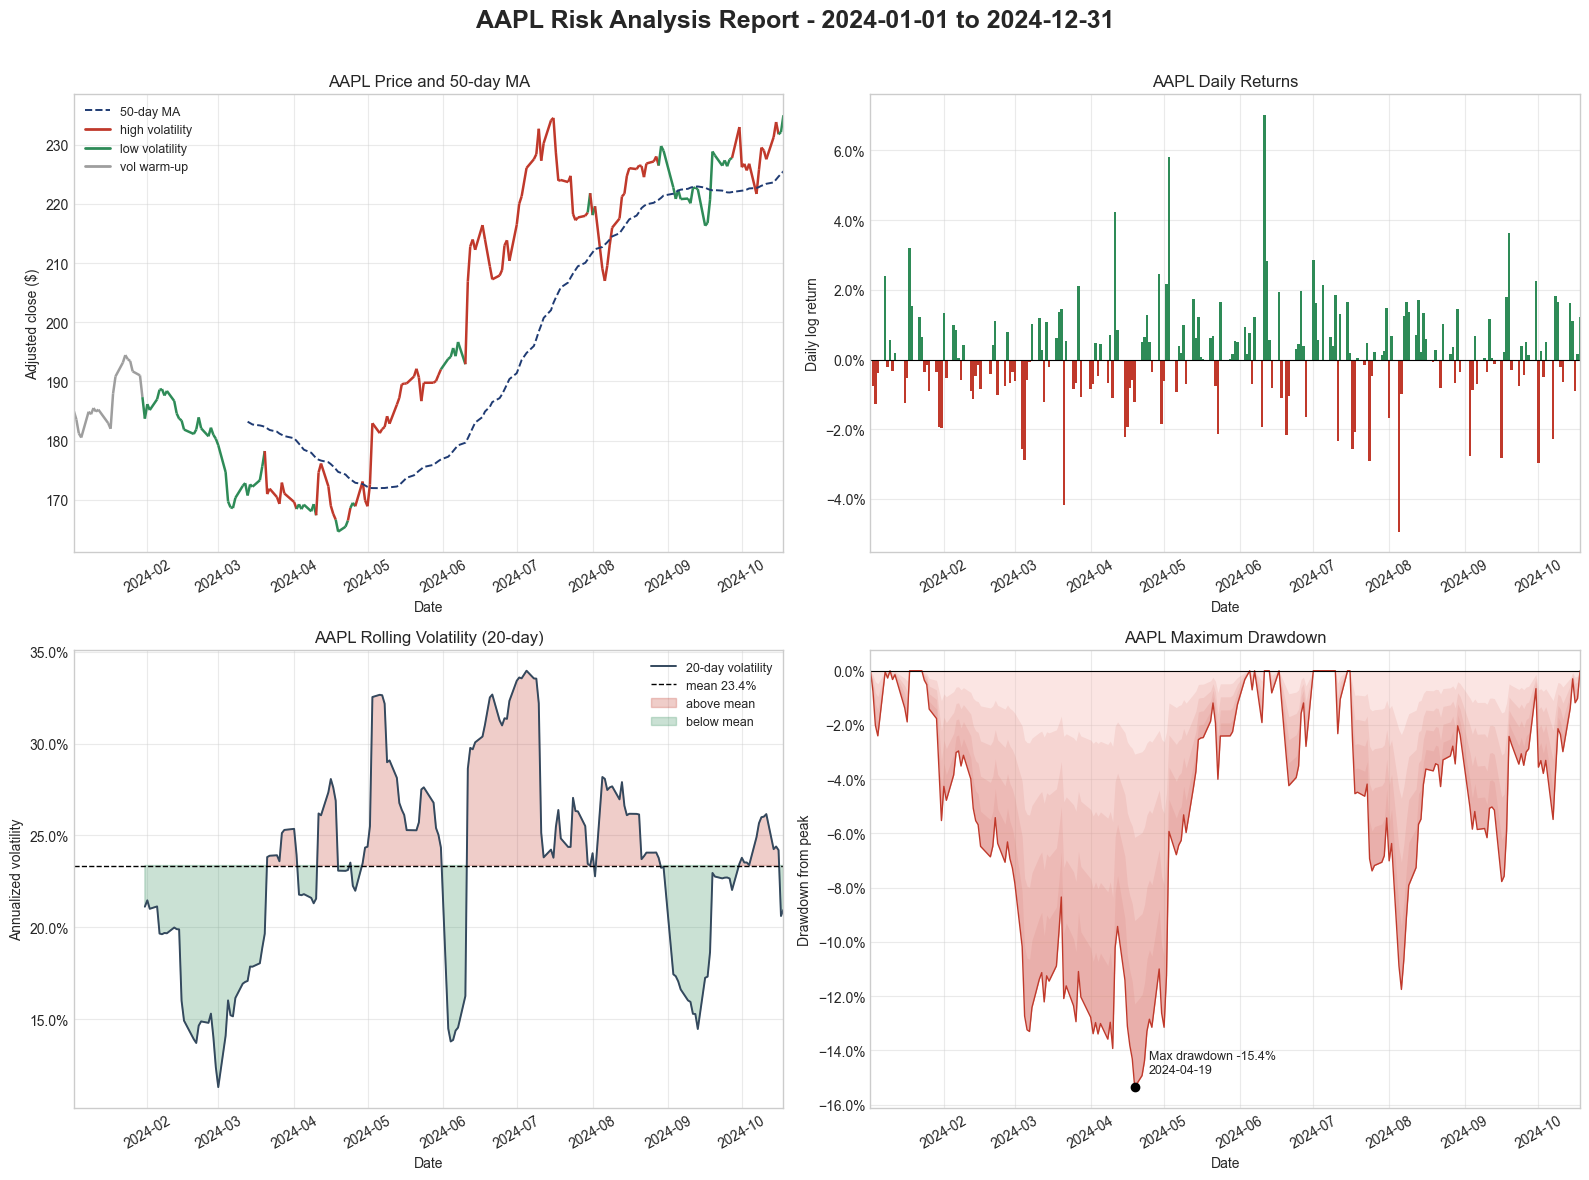

In [9]:
COLORS = {"up": "#2e8b57", "down": "#c0392b", "warmup": "#9e9e9e", "ma": "#1f3b73", "line": "#34495e"}
pct = mtick.PercentFormatter(xmax=1.0)  # precision adapts to the axis range


def plot_price(ax):
    """Adjusted close colored by volatility regime, plus the moving average."""
    x = mdates.date2num(df.index.to_pydatetime())
    y = prices.to_numpy()
    segments = np.stack([np.column_stack([x[:-1], y[:-1]]), np.column_stack([x[1:], y[1:]])], axis=1)
    vol = df["volatility"].to_numpy()[1:]  # segment i ends on day i+1: color by that day's estimate
    colors = np.where(np.isnan(vol), COLORS["warmup"], np.where(vol > mean_vol, COLORS["down"], COLORS["up"]))
    ax.add_collection(LineCollection(segments, colors=colors, linewidths=1.8))
    ax.autoscale_view()

    if df["ma"].notna().any():
        ax.plot(df.index, df["ma"], color=COLORS["ma"], lw=1.4, ls="--", label=f"{ma_window}-day MA")
    else:
        ax.text(0.02, 0.04, f"{ma_window}-day MA unavailable: only {len(df)} prices in this period",
                transform=ax.transAxes, fontsize=9, color=COLORS["ma"])
    for label, color in [("high volatility", COLORS["down"]), ("low volatility", COLORS["up"]),
                         ("vol warm-up", COLORS["warmup"])]:
        ax.plot([], [], color=color, lw=2, label=label)
    ax.legend(loc="best", fontsize=9)
    ax.set(title=f"{ticker} Price and {ma_window}-day MA", xlabel="Date", ylabel="Adjusted close ($)")


def plot_returns(ax):
    """Daily log returns as bars, green up and red down."""
    r = df["log_return"]
    ax.bar(df.index, r, width=1.0, color=np.where(r >= 0, COLORS["up"], COLORS["down"]))
    ax.axhline(0, color="black", lw=0.8)
    ax.yaxis.set_major_formatter(pct)
    ax.set(title=f"{ticker} Daily Returns", xlabel="Date", ylabel="Daily log return")


def plot_volatility(ax):
    """Rolling volatility with its mean and shaded high/low regimes."""
    v = df["volatility"]
    if v.notna().sum() == 0:
        ax.text(0.5, 0.5, f"Rolling volatility unavailable:\nneeds {volatility_window + 1} prices, have {len(df)}",
                ha="center", va="center", transform=ax.transAxes)
    else:
        ax.plot(df.index, v, color=COLORS["line"], lw=1.4, label=f"{volatility_window}-day volatility")
        ax.axhline(mean_vol, color="black", ls="--", lw=1, label=f"mean {mean_vol:.1%}")
        ax.fill_between(df.index, v, mean_vol, where=v > mean_vol, interpolate=True,
                        color=COLORS["down"], alpha=0.25, label="above mean")
        ax.fill_between(df.index, v, mean_vol, where=v <= mean_vol, interpolate=True,
                        color=COLORS["up"], alpha=0.25, label="below mean")
        ax.legend(loc="best", fontsize=9)
        ax.yaxis.set_major_formatter(pct)
    ax.set(title=f"{ticker} Rolling Volatility ({volatility_window}-day)", xlabel="Date",
           ylabel="Annualized volatility")


def plot_drawdown(ax):
    """Drawdown area with a layered red gradient and the maximum drawdown marked."""
    dd = df["drawdown"]
    for k in np.linspace(0.2, 1.0, 5):  # layered transparent fills: deeper = more layers overlap = darker
        ax.fill_between(df.index, dd * k, dd, color=COLORS["down"], alpha=0.12, lw=0)
    ax.fill_between(df.index, dd, 0, color="#f5b7b1", alpha=0.35, lw=0)
    ax.plot(df.index, dd, color=COLORS["down"], lw=1)
    trough = dd.idxmin()
    ax.scatter([trough], [dd.min()], color="black", zorder=5)
    ax.annotate(f"Max drawdown {dd.min():.1%}\n{trough.date()}", (trough, dd.min()),
                xytext=(10, 10), textcoords="offset points", fontsize=9)
    ax.axhline(0, color="black", lw=0.8)
    ax.yaxis.set_major_formatter(pct)
    ax.set(title=f"{ticker} Maximum Drawdown", xlabel="Date", ylabel="Drawdown from peak")


fig, axes = plt.subplots(2, 2, figsize=(16, 12))
plot_price(axes[0, 0])
plot_returns(axes[0, 1])
plot_volatility(axes[1, 0])
plot_drawdown(axes[1, 1])
for ax in axes.flat:
    ax.set_xlim(first_day, last_day)  # same date axis on every panel, warm-up gaps included
    ax.grid(True, alpha=0.4)
    ax.tick_params(axis="x", rotation=30)
fig.suptitle(f"{ticker} Risk Analysis Report - {start_date} to {end_date}", fontsize=18, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.97))
plt.show()

## Summary statistics

Definitions (with *n* nonmissing daily log returns):
- **Total return:** `last adjusted close / first adjusted close − 1`
- **Annualized return:** `exp(sum(log returns) × 252 / n) − 1`, compounded
- **Annualized volatility:** `std(log returns) × √252` over the whole period. This is different from the mean of the
  rolling volatility shown in the chart.
- **Sharpe ratio:** `(mean log return × 252 − 2%) / (std × √252)`
- **Maximum drawdown:** the most negative drawdown in the period
- **Best/worst day, average up/down day:** in log returns
- **Positive days:** up days as a share of **all** nonmissing returns (flat days count in the denominator)

In [10]:
def summary_statistics(prices: pd.Series, returns: pd.Series, drawdown: pd.Series, sharpe: float) -> dict:
    """Headline risk/return metrics as fractions (NaN where undefined)."""
    r = returns.dropna()
    n = len(r)
    up, down = r[r > 0], r[r < 0]
    return {
        "Total Return": prices.iloc[-1] / prices.iloc[0] - 1,
        "Annualized Return": np.exp(r.sum() * TRADING_DAYS / n) - 1 if n else np.nan,
        "Annualized Volatility": r.std(ddof=1) * np.sqrt(TRADING_DAYS) if n >= 2 else np.nan,
        "Sharpe Ratio": sharpe,
        "Maximum Drawdown": drawdown.min(),
        "Best Day": r.max() if n else np.nan,
        "Worst Day": r.min() if n else np.nan,
        "Positive Days": len(up) / n if n else np.nan,
        "Average Up Day": up.mean() if len(up) else np.nan,
        "Average Down Day": down.mean() if len(down) else np.nan,
    }


def format_metric(name: str, value: float) -> str:
    """Display formatting only: signed % for returns, plain % for rates, 2 decimals for Sharpe."""
    if value is None or not np.isfinite(value):
        return "N/A"
    if name == "Sharpe Ratio":
        return f"{value:.2f}"
    if name in ("Annualized Volatility", "Positive Days"):
        return f"{value:.1%}"
    return f"{value:+.2%}"


# Hand-worked check: prices 100 -> 110 -> 110 -> 99 (one up day, one flat day, one down day).
p = pd.Series([100.0, 110.0, 110.0, 99.0])
r = calculate_returns(p)
s = summary_statistics(p, r, calculate_max_drawdown(p), calculate_sharpe_ratio(r))
assert np.isclose(s["Total Return"], -0.01)
assert np.isclose(s["Annualized Return"], np.exp(np.log(0.99) * 252 / 3) - 1)
assert np.isclose(s["Positive Days"], 1 / 3)            # the flat day counts in the denominator
assert np.isclose(s["Average Up Day"], np.log(1.1)) and np.isclose(s["Maximum Drawdown"], -0.1)
s = summary_statistics(p.iloc[:3], r.iloc[:3], calculate_max_drawdown(p.iloc[:3]), np.nan)
assert np.isnan(s["Average Down Day"]) and format_metric("Average Down Day", s["Average Down Day"]) == "N/A"


def format_summary_table(stats: dict) -> str:
    """Render the metrics as a two-column text table (display only)."""
    lines = [f"{'Metric':<24}  Value", f"{'-' * 24}  {'-' * 8}"]
    lines += [f"{name:<24}  {format_metric(name, value)}" for name, value in stats.items()]
    return "\n".join(lines)


stats = summary_statistics(prices, df["log_return"], df["drawdown"], sharpe)
summary_table = pd.DataFrame({"Metric": list(stats), "Value": [format_metric(k, v) for k, v in stats.items()]})
print(f"{ticker}: {first_day.date()} to {last_day.date()} ({len(df)} trading days, {len(returns)} returns)\n")
print(format_summary_table(stats))

AAPL: 2024-01-02 to 2024-10-18 (202 trading days, 201 returns)

Metric                    Value
------------------------  --------
Total Return              +27.07%
Annualized Return         +35.03%
Annualized Volatility     23.6%
Sharpe Ratio              1.19
Maximum Drawdown          -15.35%
Best Day                  +7.01%
Worst Day                 -4.94%
Positive Days             55.7%
Average Up Day            +1.08%
Average Down Day          -1.09%


## Outputs for the batch run

Named values are saved with scrapbook, so `03_run_all_stocks.py` can collect results from each executed report
instead of parsing its text. Values are plain floats in fraction units, and `NaN` means undefined.

In [11]:
def as_float(x):
    """Plain Python float (NaN stays NaN) so scraps serialize cleanly."""
    return float(x) if x is not None and np.isfinite(x) else float("nan")


scraps = {
    "ticker": ticker,
    "start_date": start.strftime("%Y-%m-%d"),
    "end_date": end.strftime("%Y-%m-%d"),
    "first_date": first_day.strftime("%Y-%m-%d"),
    "last_date": last_day.strftime("%Y-%m-%d"),
    "trading_days": int(len(df)),
    "n_returns": int(len(returns)),
    "avg_daily_return": as_float(returns.mean()),
    "avg_volatility": as_float(mean_vol),
    "max_drawdown": as_float(stats["Maximum Drawdown"]),
    "sharpe_ratio": as_float(sharpe),
    "total_return": as_float(stats["Total Return"]),
    "annualized_return": as_float(stats["Annualized Return"]),
    "annualized_volatility": as_float(stats["Annualized Volatility"]),
}
for name, value in scraps.items():
    sb.glue(name, value)
sb.glue("summary", {k: as_float(v) for k, v in stats.items()})
sb.glue("report_figure", fig, encoder="display", display=False)
print(f"Glued {len(scraps) + 2} scraps for {ticker}.")

Glued 16 scraps for AAPL.
